# Modelos y Simulación — Trabajo Práctico 6

## Punto 3: Ajuste de conjuntos de distinta clase de muestra

Se estiman los parámetros de Cole a partir de conjuntos experimentales de una muestra humana, una vegetal y un fantoma de agar de la base abierta indicada en la consigna. La finalidad es evaluar con el mismo procedimiento cuánto describe el modelo de una dispersión distintas curvas experimentales, incluyendo sus discrepancias.

Se utiliza el signo **más confirmado por el docente**:

$$Z(f)=R_\infty+\frac{R_0-R_\infty}{1+(jf/f_c)^\alpha},\qquad \tau=\frac{1}{2\pi f_c}.$$

Este trabajo resuelve únicamente el punto 3. Los puntos 1 y 2 se conservan exclusivamente en `../Tp6Claude/`, sin modificaciones. La función de impedancia de `ajuste_cole.py` es la predicción necesaria para ajustar los parámetros.


In [1]:
from pathlib import Path
import sys
import importlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

BASE = next((p for p in [Path.cwd(), Path.cwd()/'trabajos'/'Tp6'] if (p/'ajuste_cole.py').exists()), None)
if BASE is None:
    raise FileNotFoundError('Abrir desde la raíz del repositorio o desde trabajos/Tp6.')
if str(BASE) not in sys.path:
    sys.path.insert(0, str(BASE))
import ajuste_cole as ajuste
importlib.reload(ajuste)
print('Intérprete:', sys.executable)
registros = ajuste.cargar_datos()
print('Archivos originales: checksums correctos. Registros:', len(registros))

Intérprete: /home/ro/Desktop/facu/MyS/MySss/.conda-env/bin/python
Archivos originales: checksums correctos. Registros: 1457


## Qué se considera un conjunto de datos y por qué se elige

La base `registros_EIS.mat` contiene 1457 registros. Cada registro incluye una matriz `eis`: un barrido de frecuencias completo con resistencia, reactancia, módulo y fase. Por eso cada barrido constituye un conjunto de datos para ajustar una curva; no es un único punto. En esta selección hay **tres conjuntos y 406 puntos de medición**, con parte real e imaginaria en cada frecuencia.

Se usa variedad de clases para evaluar la aplicabilidad del mismo modelo. No se pretende representar estadísticamente toda la base ni demostrar diferencias biológicas entre grupos con una curva por clase.

### Criterios fijados antes de calcular los ajustes

1. **Clases de interés:** humana, vegetal y fantoma de agar, identificadas por los metadatos `sample=1,2,5`. No se atribuyen especies, órganos o personas concretas que la documentación no identifica.
2. **Procedencia interpretable:** para humanos se considera únicamente el grupo 001–050 de Ayllón et al., documentado como libre de los errores introducidos en los grupos posteriores. Para vegetales se usa `origin=5` y para fantomas `origin=1`. No se afirma que estos dos últimos grupos estén certificados como libres de errores.
3. **Integridad y eje frecuencial:** al menos 30 frecuencias positivas, distintas y ordenables, sin puntos no finitos ni resistencias negativas; banda compatible con la declarada y unidades interpretables, con las reservas explicadas abajo.
4. **Dispersión observable antes de ajustar:** al menos el 80% de las reactancias deben ser negativas y el mínimo de Im(Z) debe tener cinco o más frecuencias a cada lado. Se permite hasta un 20% de puntos con otra respuesta para conservar discrepancias. Estos umbrales son reglas operativas de este trabajo, no una norma de calidad instrumental. El mínimo observado es una señal de una transición interior, no una prueba de que haya una sola dispersión ni de que todos los parámetros sean identificables.
5. **Elección reproducible:** entre los candidatos que cumplen, se toma el menor ID numérico de cada clase. No se usa el error de ajuste como criterio. El orden de los IDs no tiene significado biológico; se usa sólo para evitar una elección subjetiva entre candidatos.

La auditoría de todos los registros, incluyendo elegibilidad, motivo y selección, se exporta a `resultados/auditoria_seleccion.csv`. Cumplen los controles 50 curvas humanas, 28 vegetales y 95 de fantomas. Esto da lugar a:

| Conjunto | Clase | N | Equipo | Electrodos | Fuente según metadatos |
|---|---|---:|---|---|---|
| ID001 | Humana | 256 | SFB7 Impedimed | Tetrapolar | Ayllón et al. |
| ID1233 | Vegetal | 100 | HF2IS Zurich Instruments | No informado | Bertemes Filho |
| ID1311 | Fantoma de agar | 50 | Solartron | Bipolar | Dell’Osa et al. |

No se incluyen otras clases porque se acotó el objetivo a estas tres. En particular no se interpreta la exclusión de la clase animal como evidencia de mala calidad de todas sus mediciones. `Data_detail.txt` contiene un intervalo mal escrito para Bertemes Filho; se priorizan los campos `sample`, `origin` y `device` de los propios registros frente a ese intervalo textual inconsistente.

### Cómo defender la elección

> Elegí un barrido humano, uno vegetal y uno de un fantoma para evaluar el modelo en clases de muestra distintas. Revisé su procedencia, unidades, integridad y que hubiera puntos a ambos lados de la dispersión observada. Dentro de cada clase tomé el primer ID que cumplía esos controles, antes de ajustar. Usé el mismo método en los tres y conservé también el caso que ajustó mal para discutir las limitaciones del modelo.


In [2]:
# Esta celda selecciona sin ejecutar ningún ajuste.
seleccionados, auditoria = ajuste.seleccionar_registros(registros)
display(auditoria.groupby('muestra_codigo')[['elegible','seleccionada']].sum())
display(auditoria.loc[auditoria.seleccionada])
print('Elegidos:', [r['id'] for r in seleccionados])
print('Auditoría completa: resultados/auditoria_seleccion.csv')

,elegible,seleccionada
muestra_codigo,,
1,50,1
2,28,1
4,0,0
5,95,1


,id,muestra_codigo,origen,seleccionada,elegible,n,descartados,conversion,fmin_Hz,fmax_Hz,fraccion_X_negativa,f_pico_observado_Hz,puntos_antes_pico,puntos_despues_pico,motivo
0,001,1,4,True,True,256.0,0.0,rad/s → Hz: eje original / (2π),3083.945332,1.000002e+06,1.00,38961.130069,112.0,143.0,Primer ID elegible de su clase; elegido sin aj...
1232,1233,2,5,True,True,100.0,0.0,Hz: eje compatible con 400 Hz–1 MHz,400.000000,1.000000e+06,0.87,3656.735341,28.0,71.0,Primer ID elegible de su clase; elegido sin aj...
1310,1311,5,1,True,True,50.0,0.0,Hz: sin conversión,1.000000,6.500000e+04,0.88,19.953000,13.0,36.0,Primer ID elegible de su clase; elegido sin aj...


Elegidos: ['001', '1233', '1311']
Auditoría completa: resultados/auditoria_seleccion.csv


## Fuente, unidades y preparación

Se conserva la base original de Dell’Osa, Bravo y Villanueva Jousset (2025), *Single dispersion EIS measurements: a compilation*, versión v1, [Zenodo, DOI 10.5281/zenodo.15795175](https://doi.org/10.5281/zenodo.15795175). El enunciado menciona 2024, pero el registro publicado es de 2025. Se verifican los checksums MD5 de los cuatro archivos descargados. Los datos originales no se modifican y no hace falta conexión para repetir los cálculos.

Las cinco columnas de `eis` son eje frecuencial, Re(Z), Im(Z), módulo y fase. Se usan las tres primeras. Módulo y fase son cantidades derivadas y no se agregan como observaciones independientes.

- **ID001:** el eje original va de 19377 a 6283200. Frente al rango declarado de 3 kHz–1 MHz, se interpreta como rad/s y se divide por $2\pi$, obteniendo aproximadamente 3083.95 Hz–1000002.34 Hz. Es una **inferencia de unidades por consistencia**, no una unidad explícita del README. Si se interpretara como Hz, fc se multiplicaría por $2\pi$ y τ se dividiría por ese factor, sin cambiar las resistencias, α ni los errores.
- **ID1233:** el eje va de 400 a 1000000, compatible directamente con el rango declarado de 400 Hz–1 MHz. Se interpreta en Hz. Su configuración de electrodos figura como ausente; no se completa por suposición.
- **ID1311:** el eje va de 1 a 65000, compatible con el rango declarado de 1 Hz–65 kHz. Se conserva en Hz.

Se ordenan frecuencias y se verifican finitud y positividad. No hubo puntos descartados en los conjuntos elegidos. **Se mantiene toda la banda y el signo original de la reactancia**, incluso cuando cambia de signo. El requisito de 80% de reactancia negativa selecciona curvas; no elimina el otro 20% de sus puntos.

### Datos observados antes de ajustar


Cada columna corresponde a un conjunto y tiene su propia escala vertical. La línea marca el mínimo observado de la reactancia. La medición humana tiene reactancia negativa en el 100% de los puntos; la vegetal en el 87% y el fantoma en el 88%. Los puntos de signo opuesto se conservan.

,ID,muestra,N,fmin_Hz,fmax_Hz,conversion,descartados
0,001,Humana,256,3083.945332,1.000002e+06,rad/s → Hz: eje original / (2π),0
1,1233,Vegetal,100,400.000000,1.000000e+06,Hz: eje compatible con 400 Hz–1 MHz,0
2,1311,Fantoma de agar,50,1.000000,6.500000e+04,Hz: sin conversión,0


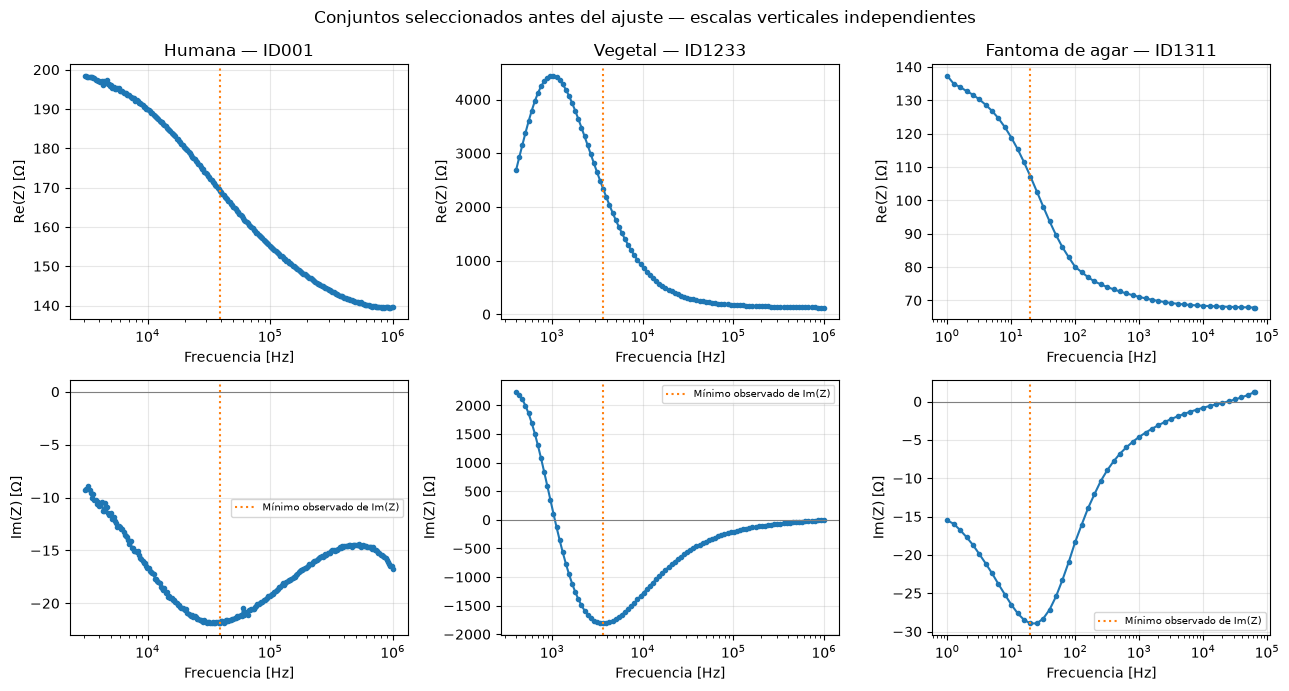

In [3]:
inventario = []
for r in seleccionados:
    f, z, conversion, descartados = ajuste.preparar_registro(r)
    np.testing.assert_allclose(np.abs(r['eis'][:,1]+1j*r['eis'][:,2]), r['eis'][:,3])
    inventario.append({'ID':r['id'], 'muestra':ajuste.MUESTRAS[str(r['sample'])],
                      'N':len(f), 'fmin_Hz':f.min(), 'fmax_Hz':f.max(),
                      'conversion':conversion, 'descartados':descartados})
display(pd.DataFrame(inventario))
fig = ajuste.graficar_datos_seleccionados(seleccionados)
plt.show()

## Método común de ajuste

Se minimiza conjuntamente el error de resistencia y reactancia mediante `scipy.optimize.least_squares`:

$$S(\mathbf p)=\sum_i\left[(\operatorname{Re}Z(f_i;\mathbf p)-R_i)^2+(\operatorname{Im}Z(f_i;\mathbf p)-X_i)^2\right],\quad \mathbf p=(R_0,R_\infty,f_c,\alpha).$$

Ambas componentes y todos los puntos reciben igual peso en ohmios: no hay incertidumbres por punto para justificar otros pesos. Una escala global mejora el cálculo numérico, pero no cambia el mínimo. Ajustar las dos componentes incorpora la información de fase; ajustar sólo el módulo podría ocultar discrepancias de signo.

Se optimizan $\log R_\infty$, $\log(R_0-R_\infty)$, $\log f_c$ y α, imponiendo $R_0>R_\infty>0$ y $0.01\leq\alpha\leq1$. Las resistencias internas están limitadas entre $10^{-6}$ y $10^8$ Ω y fc entre $f_{\min}/100$ y $100f_{\max}$.

Se prueban 15 inicios por conjunto: cinco frecuencias iniciales logarítmicas dentro de la banda y tres exponentes iniciales, 0.35, 0.7 y 0.95. Se conserva el menor costo entre soluciones convergentes. Los 15 inicios convergieron en cada caso; esto no garantiza un mínimo global. En el vegetal la solución alcanza el límite α=1, lo que se informa en lugar de cambiar la muestra o el modelo.

Se repite el ajuste con frecuencias alternas y se evalúan las restantes como control de interpolación. Esta validación usa el mismo registro y no valida otros sujetos ni extrapolaciones.


In [4]:
# Mismo procedimiento y pesos para los tres conjuntos completos.
resumen, curvas = ajuste.resolver_ajustes(registros)
assert (resumen.signo_modelo == 1).all()
display(resumen[['id','muestra','R0_ohm','Rinf_ohm','fc_Hz','tau_s','alpha','parametro_en_limite']])
display(resumen[['id','RMSE_complejo_ohm','NRMSE_porcentaje','RMSE_validacion_ohm',
                 'inicios_convergentes','condicion_jacobiano']])

,id,muestra,R0_ohm,Rinf_ohm,fc_Hz,tau_s,alpha,parametro_en_limite
0,001,Humana,211.943580,125.030313,44992.971363,0.000004,0.563853,False
1,1233,Vegetal,3766.118645,180.459160,5469.107933,0.000029,1.000000,True
2,1311,Fantoma de agar,148.596899,67.338445,16.606233,0.009584,0.682638,False


,id,RMSE_complejo_ohm,NRMSE_porcentaje,RMSE_validacion_ohm,inicios_convergentes,condicion_jacobiano
0,001,2.409617,1.431559,2.442245,15,28.213303
1,1233,760.750188,32.830204,735.442072,15,19.140700
2,1311,3.615363,3.872031,3.544132,15,12.714201


## Parámetros y cobertura

| ID | Muestra | R₀ [Ω] | R∞ [Ω] | fc [Hz] | τ [µs] | α | Límite activo |
| --- | --- | --- | --- | --- | --- | --- | --- |
| 001 | Humana | 211.944 | 125.030 | 44992.971 | 3.537 | 0.563853 | False |
| 1233 | Vegetal | 3766.119 | 180.459 | 5469.108 | 29.101 | 1.000000 | True |
| 1311 | Fantoma de agar | 148.597 | 67.338 | 16.606 | 9584.048 | 0.682638 | False |

Los valores de fc se informan en Hz, no en kHz. τ se muestra en microsegundos para facilitar la lectura. R₀ y R∞ son límites extrapolados, no la primera y última resistencia medidas.

La cobertura alrededor del mínimo observado se revisó antes de ajustar. Después se cuantificó la banda disponible a cada lado de fc estimada:

| ID | Mínimo observado de Im(Z) [Hz] | Puntos antes/después | Décadas bajo fc ajustada | Décadas sobre fc ajustada |
| --- | --- | --- | --- | --- |
| 001 | 38961.130 | 112/143 | 1.164 | 1.347 |
| 1233 | 3656.735 | 28/71 | 1.136 | 2.262 |
| 1311 | 19.953 | 13/36 | 1.220 | 3.593 |

Una década representa un factor diez. En los tres casos hay más de una década a cada lado de fc ajustada, pero eso no implica que la banda ya alcance ambos límites resistivos. El mínimo medido no tiene por qué coincidir con fc del ajuste, especialmente si el modelo no describe adecuadamente la curva.

## Errores y control de interpolación

$$\mathrm{RMSE}_c=\sqrt{\frac1N\sum_i|Z_{\mathrm{ajuste},i}-Z_{\mathrm{medido},i}|^2},\qquad
\mathrm{NRMSE}=100\frac{\mathrm{RMSE}_c}{\sqrt{\frac1N\sum_i|Z_{\mathrm{medido},i}|^2}}.$$

Se divide por N, no por 2N: cada frecuencia combina el error de ambas componentes. El error relativo medio es $100\operatorname{mean}(|\Delta Z_i|/|Z_i|)$.

| ID | RMSE complejo [Ω] | NRMSE [%] | Error relativo medio [%] | RMSE validación [Ω] |
| --- | --- | --- | --- | --- |
| 001 | 2.410 | 1.432 | 1.183 | 2.442 |
| 1233 | 760.750 | 32.830 | 20.675 | 735.442 |
| 1311 | 3.615 | 3.872 | 2.759 | 3.544 |

Los errores de validación son del mismo orden que los de entrenamiento. Eso respalda la consistencia de la interpolación, pero no elimina el sesgo de un modelo inadecuado. Los errores absolutos dependen de la escala de impedancia; el NRMSE facilita su lectura, aunque una resistencia grande puede ocultar discrepancias importantes de reactancia.


## Conjunto ID001 — Humana

El ajuste describe la caída de resistencia y la dispersión principal, con NRMSE ≈1.43%. Ningún parámetro queda en un límite activo. En la parte alta de la banda, la reactancia medida vuelve a aumentar en magnitud mientras la de una sola dispersión tiende a cero. Los residuos tienen estructura y no pueden interpretarse sólo como ruido aleatorio.

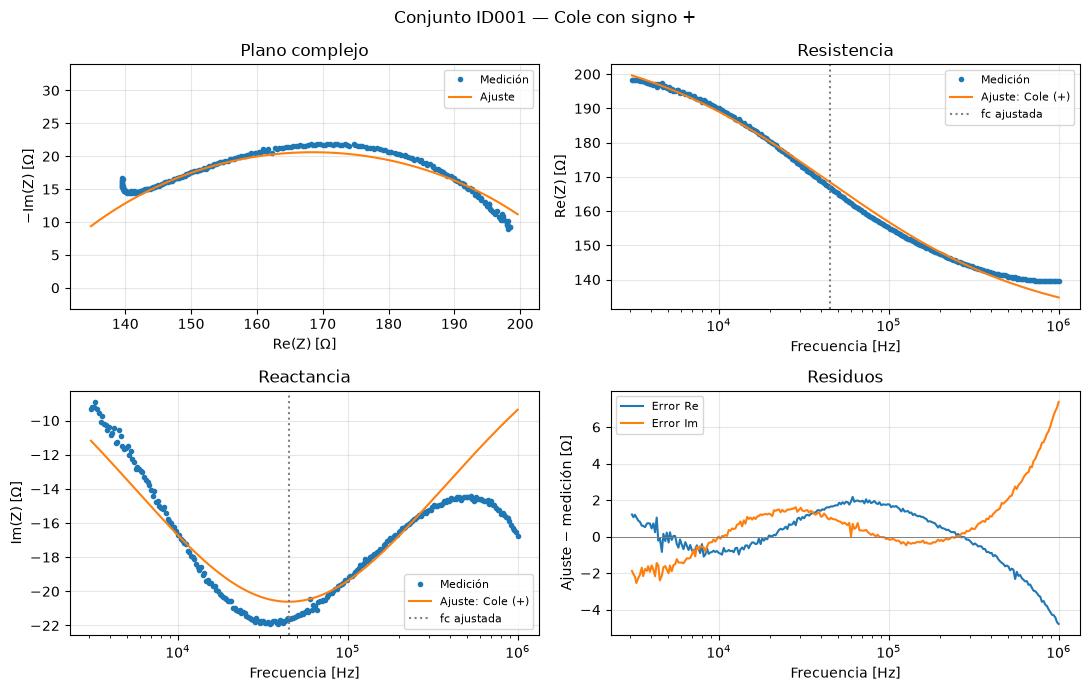

In [5]:
f, z, p = curvas['001']
fig = ajuste.graficar_ajuste('001', f, z, p)
plt.show()

## Conjunto ID1233 — Vegetal

El NRMSE es ≈32.83% y α alcanza el límite superior 1. El modelo no proporciona una descripción satisfactoria del conjunto completo. En las frecuencias más bajas hay reactancia positiva elevada, incompatible con el signo negativo que predice Cole con estos parámetros. También se observan desviaciones en la forma de la dispersión.

Se conservan los 100 puntos y el resultado desfavorable. No se cambia el signo de esos puntos, no se recorta la banda ni se sustituye el conjunto por otro elegido por menor error. Los valores de la tabla son la solución restringida del optimizador, **no una caracterización física confiable del vegetal**. La causa de la discrepancia no puede identificarse con la documentación disponible. Serían necesarios más datos del montaje o una justificación independiente de otro modelo o banda antes de atribuir propiedades al material.

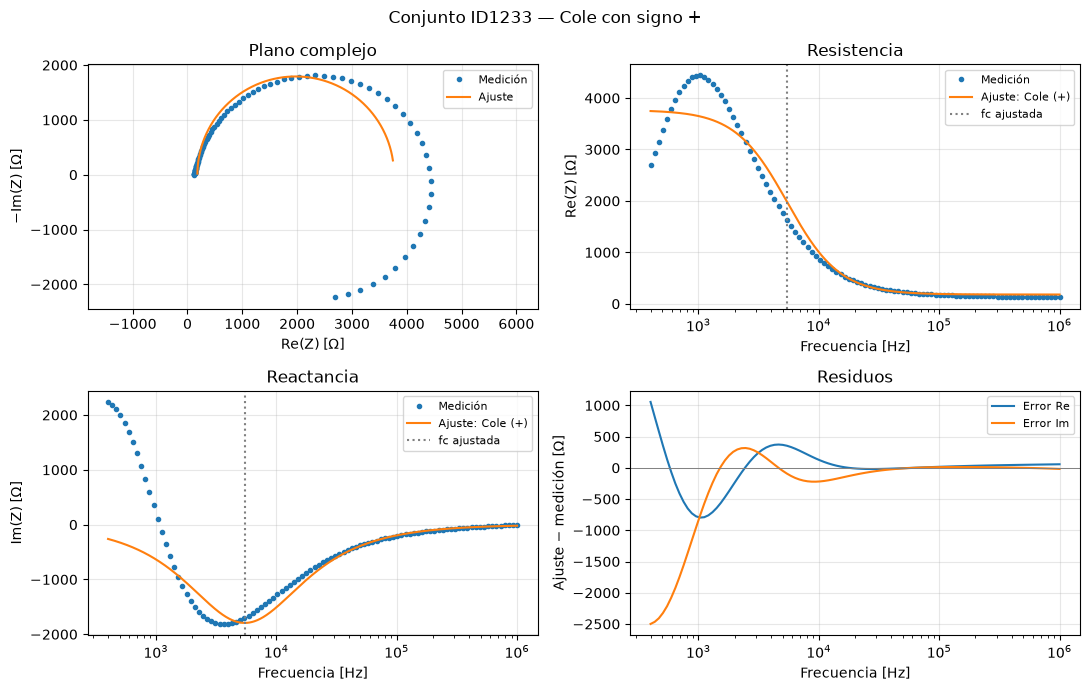

In [6]:
f, z, p = curvas['1233']
fig = ajuste.graficar_ajuste('1233', f, z, p)
plt.show()

## Conjunto ID1311 — Fantoma de agar

El modelo describe una dispersión en decenas de Hz, con NRMSE ≈3.87%. Subestima el máximo de la reactancia en magnitud y no representa su cambio de signo al final de la banda. No hay parámetros en límites activos. Al ser una medición bipolar, no corresponde separar por este ajuste la contribución del fantoma y la de sus contactos.

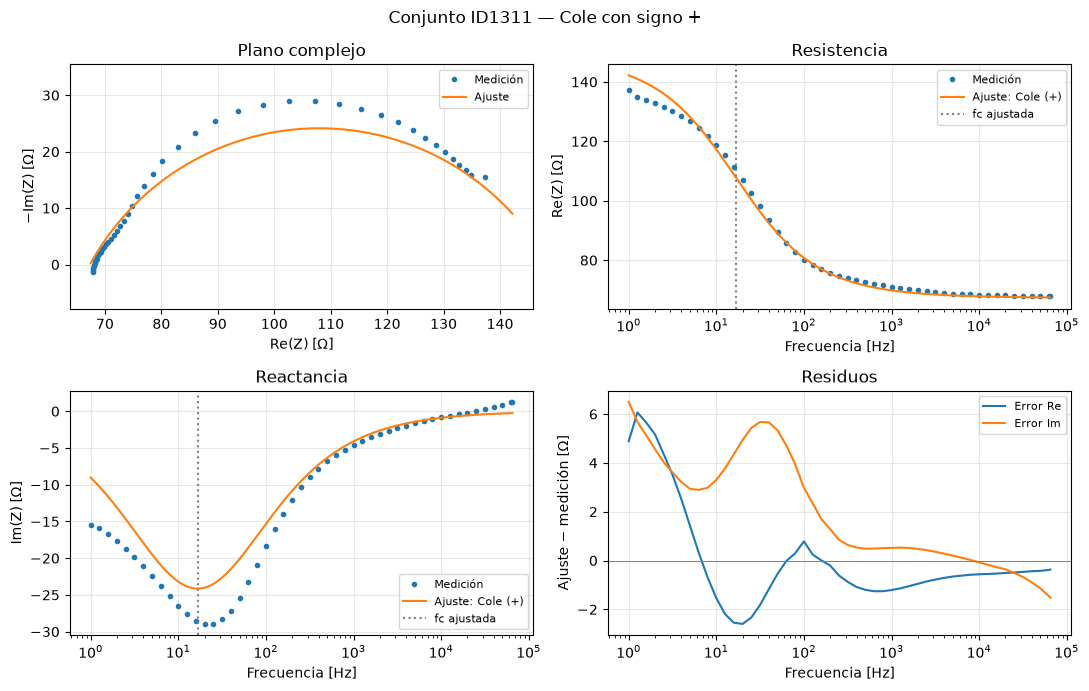

In [7]:
f, z, p = curvas['1311']
fig = ajuste.graficar_ajuste('1311', f, z, p)
plt.show()

## Alcance y conclusiones

Se eligieron tres barridos de distinta clase de muestra mediante reglas reproducibles anteriores al ajuste. Se usó la misma función objetivo y se conservaron todos los puntos. La selección y las exclusiones pueden revisarse en `auditoria_seleccion.csv`.

El modelo describe razonablemente la tendencia principal del conjunto humano y del fantoma, aunque sus residuos revelan efectos adicionales. En el vegetal, el error grande y el límite activo de α muestran que el Cole de una dispersión no caracteriza satisfactoriamente el barrido completo. No basta con que el optimizador converja para considerar adecuados sus parámetros.

No se puede atribuir la diferencia entre parámetros exclusivamente a la clase de material: cambian equipos, configuraciones y frecuencias. Una muestra por clase no permite inferencia estadística sobre cada clase ni identificar tejidos concretos. Tampoco se puede asegurar precisión experimental por los decimales de las tablas. No se calculan intervalos de confianza, porque no se dispone de un modelo de ruido y hay residuos correlacionados y una solución en el límite.

## Referencias y reproducción

- Consigna local: `../TP6 - MyS - 2026.pdf`, usando el signo más confirmado por el docente.
- Dell’Osa, A. H., Bravo, N. Y. y Villanueva Jousset, T. (2025). *Single dispersion EIS measurements: a compilation*, versión v1. [Zenodo](https://doi.org/10.5281/zenodo.15795175). Licencia CC BY 4.0 según sus metadatos. Se conservan `readme_en.txt`, `Data_detail.txt`, `references.txt`, la matriz original y los metadatos en `datos/`.

`Punto3.ipynb` ejecuta la selección antes del ajuste mediante `ajuste_cole.py`. `resultados/` contiene la auditoría, parámetros y los tres conjuntos completos con predicciones y residuos. La columna `signo_modelo=1` identifica la fórmula. No hace falta volver a descargar datos. Los puntos 1 y 2 permanecen exclusivamente en `../Tp6Claude/`.
